# Molecular Descriptor Calculation and Validation Using RDKit

## Objective
This project calculates physicochemical descriptors for molecules from SMILES strings using RDKit. It validates the results and visualises them.

## Tools Used
Python, RDKit, pandas, NumPy, Matplotlib, Jupyter Notebook

## 1. Setup and Library Check
Install check for RDKit and import of all required libraries.

In [1]:
import rdkit

print("RDKit is successfully installed!")
print("RDKit version:", rdkit.__version__)

RDKit is successfully installed!
RDKit version: 2026.09.2


In [2]:
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import rdMolDescriptors

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. SMILES Parsing and Molecule Drawing
Converting a SMILES string into an RDKit molecule object and drawing its 2D structure.

In [3]:
# Convert SMILES into a molecular structure

In [4]:
from rdkit import Chem

smiles = "CCO"

mol = Chem.MolFromSmiles(smiles)

print(mol)

In [5]:
# Draw the molecule

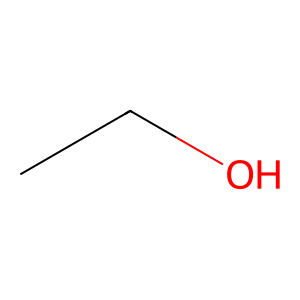

In [6]:
from rdkit.Chem import Draw

Draw.MolToImage(mol)

## 3. Molecular Descriptor Calculation
Calculating key physicochemical descriptors for a single molecule (ethanol): molecular weight, LogP, TPSA, hydrogen bond donors and acceptors, rotatable bonds, ring count, heavy atom count, and Fraction CSP3.

In [7]:
# Calculate molecular descriptors

In [8]:
# Calculate molecular weight

In [9]:
molecular_weight = Descriptors.MolWt(mol)

print("Molecular Weight:", molecular_weight)

Molecular Weight: 46.069


In [10]:
# Calculate LogP

In [11]:
logp = Descriptors.MolLogP(mol)

print("LogP:", logp)

LogP: -0.0014000000000000123


In [12]:
# Calculate TPSA

In [13]:
tpsa = Descriptors.TPSA(mol)

print("TPSA:", tpsa)

TPSA: 20.23


In [14]:
# Calculate hydrogen-bond donors and acceptors

In [15]:
hbd = Descriptors.NumHDonors(mol)

hba = Descriptors.NumHAcceptors(mol)

print("Hydrogen Bond Donors:", hbd)
print("Hydrogen Bond Acceptors:", hba)

Hydrogen Bond Donors: 1
Hydrogen Bond Acceptors: 1


In [16]:
# Calculate additional descriptors

In [17]:
rotatable_bonds = Descriptors.NumRotatableBonds(mol)

ring_count = Descriptors.RingCount(mol)

heavy_atoms = Descriptors.HeavyAtomCount(mol)

fraction_csp3 = Descriptors.FractionCSP3(mol)

print("Rotatable Bonds:", rotatable_bonds)
print("Ring Count:", ring_count)
print("Heavy Atom Count:", heavy_atoms)
print("Fraction Csp3:", fraction_csp3)

Rotatable Bonds: 0
Ring Count: 0
Heavy Atom Count: 3
Fraction Csp3: 1.0


## 4. Reusable Descriptor Calculator
A function that takes any SMILES string and returns all descriptors in a dictionary, including exact molecular weight and QED (drug-likeness score). It returns None if the SMILES is invalid.

In [18]:
# Build a complete descriptor calculator

In [19]:
# Create a descriptor calculation function

In [20]:
def calculate_descriptors(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    descriptors = {

        "Molecular_Weight": Descriptors.MolWt(mol),

        "Exact_Molecular_Weight": Descriptors.ExactMolWt(mol),

        "LogP": Descriptors.MolLogP(mol),

        "TPSA": Descriptors.TPSA(mol),

        "HBD": Descriptors.NumHDonors(mol),

        "HBA": Descriptors.NumHAcceptors(mol),

        "Rotatable_Bonds": Descriptors.NumRotatableBonds(mol),

        "Ring_Count": Descriptors.RingCount(mol),

        "Heavy_Atom_Count": Descriptors.HeavyAtomCount(mol),

        "Fraction_CSP3": Descriptors.FractionCSP3(mol),

        "QED": Descriptors.qed(mol)

    }

    return descriptors

In [21]:
# Test your function

In [22]:
smiles = "CCO"

result = calculate_descriptors(smiles)

print(result)

{'Molecular_Weight': 46.069, 'Exact_Molecular_Weight': 46.041864812, 'LogP': -0.0014000000000000123, 'TPSA': 20.23, 'HBD': 1, 'HBA': 1, 'Rotatable_Bonds': 0, 'Ring_Count': 0, 'Heavy_Atom_Count': 3, 'Fraction_CSP3': 1.0, 'QED': 0.4068079656553945}


## 5. Batch Processing and CSV Export
Calculating descriptors for multiple molecules (ethanol, methane, acetic acid, aspirin, caffeine), collecting them into a pandas DataFrame, and saving the results as a CSV file.

In [23]:
# Calculate descriptors for multiple molecules

In [24]:
molecules = {

    "Ethanol": "CCO",

    "Methane": "C",

    "Acetic_Acid": "CC(=O)O",

    "Aspirin": "CC(=O)Oc1ccccc1C(=O)O",

    "Caffeine": "Cn1c(=O)c2c(ncn2C)n(C)c1=O"

}

In [25]:
# Calculate descriptors for all molecules

In [26]:
results = []

for name, smiles in molecules.items():

    descriptors = calculate_descriptors(smiles)

    if descriptors is not None:

        descriptors["Molecule"] = name

        descriptors["SMILES"] = smiles

        results.append(descriptors)

df = pd.DataFrame(results)

print(df)

   Molecular_Weight  Exact_Molecular_Weight    LogP   TPSA  HBD  HBA  \
0            46.069               46.041865 -0.0014  20.23    1    1   
1            16.043               16.031300  0.6361   0.00    0    0   
2            60.052               60.021129  0.0909  37.30    1    1   
3           180.159              180.042259  1.3101  63.60    1    3   
4           194.194              194.080376 -1.0293  61.82    0    3   

   Rotatable_Bonds  Ring_Count  Heavy_Atom_Count  Fraction_CSP3       QED  \
0                0           0                 3       1.000000  0.406808   
1                0           0                 1       1.000000  0.359785   
2                0           0                 4       0.500000  0.429883   
3                2           1                13       0.111111  0.550122   
4                0           2                14       0.375000  0.538463   

      Molecule                      SMILES  
0      Ethanol                         CCO  
1      Methane

In [27]:
# Save the results in CSV format

In [28]:
df.to_csv(
    "calculated_descriptors.csv",
    index=False
)

print("Descriptor results saved successfully!")

Descriptor results saved successfully!


## 6. Validation and Testing
Checking that the calculations are reliable: handling of invalid SMILES, molecular weight validation against a known value, a finite-value check across descriptors, and a reproducibility test.

In [29]:
# Test invalid SMILES

In [30]:
invalid_smiles = "XYZ123"

mol = Chem.MolFromSmiles(invalid_smiles)

print(mol)

None


In [31]:
# Validate molecular weight

In [32]:
smiles = "CCO"

mol = Chem.MolFromSmiles(smiles)

calculated_mw = Descriptors.MolWt(mol)

expected_mw = 46.069

tolerance = 0.01

if abs(calculated_mw - expected_mw) <= tolerance:

    print("PASS: Molecular weight validation successful")

else:

    print("FAIL: Molecular weight validation failed")

PASS: Molecular weight validation successful


In [33]:
# Validate multiple descriptors

In [34]:
def validate_descriptors(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return "FAIL: Invalid SMILES"

    checks = {

        "Molecular_Weight":
        Descriptors.MolWt(mol),

        "LogP":
        Descriptors.MolLogP(mol),

        "TPSA":
        Descriptors.TPSA(mol),

        "HBD":
        Descriptors.NumHDonors(mol),

        "HBA":
        Descriptors.NumHAcceptors(mol)

    }

    for name, value in checks.items():

        if not np.isfinite(value):

            return f"FAIL: Invalid value in {name}"

    return "PASS: All descriptors are finite"

In [35]:
print(validate_descriptors("CCO"))

print(validate_descriptors("XYZ123"))

PASS: All descriptors are finite
FAIL: Invalid SMILES


In [36]:
# Test reproducibility

In [37]:
result1 = calculate_descriptors("CCO")

result2 = calculate_descriptors("CCO")

assert result1 == result2

print("PASS: Reproducibility test successful")

PASS: Reproducibility test successful


## 7. Visualisation
Comparing the molecular weights of the five molecules using a bar chart.

In [38]:
# Visualise your results

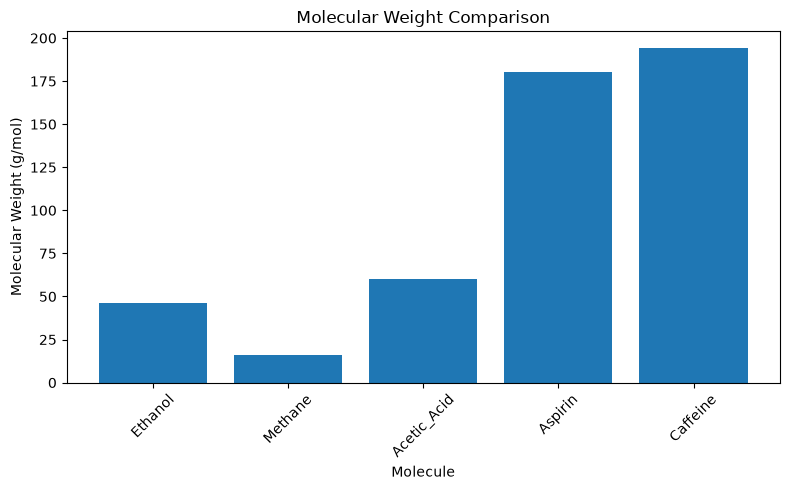

In [39]:
plt.figure(figsize=(8, 5))

plt.bar(
    df["Molecule"],
    df["Molecular_Weight"]
)

plt.xlabel("Molecule")

plt.ylabel("Molecular Weight (g/mol)")

plt.title("Molecular Weight Comparison")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

## 8. Lipinski Rule of Five Analysis
Lipinski's Rule of Five estimates whether a molecule is likely to be orally drug-like. A molecule is generally considered drug-like if it has at most one violation of these limits: molecular weight ≤ 500, LogP ≤ 5, hydrogen bond donors ≤ 5, hydrogen bond acceptors ≤ 10.

In [40]:
def lipinski_check(row):
    violations = 0
    if row["Molecular_Weight"] > 500:
        violations += 1
    if row["LogP"] > 5:
        violations += 1
    if row["HBD"] > 5:
        violations += 1
    if row["HBA"] > 10:
        violations += 1
    return violations

df["Lipinski_Violations"] = df.apply(lipinski_check, axis=1)
df["Drug_Like"] = df["Lipinski_Violations"] <= 1

print(df[["Molecule", "Molecular_Weight", "LogP", "HBD", "HBA", "Lipinski_Violations", "Drug_Like"]])

      Molecule  Molecular_Weight    LogP  HBD  HBA  Lipinski_Violations  \
0      Ethanol            46.069 -0.0014    1    1                    0   
1      Methane            16.043  0.6361    0    0                    0   
2  Acetic_Acid            60.052  0.0909    1    1                    0   
3      Aspirin           180.159  1.3101    1    3                    0   
4     Caffeine           194.194 -1.0293    0    3                    0   

   Drug_Like  
0       True  
1       True  
2       True  
3       True  
4       True  


## 9. QED Drug-Likeness Comparison
QED (Quantitative Estimate of Drug-likeness) combines several properties into a single score between 0 and 1. Higher values indicate more drug-like molecules.

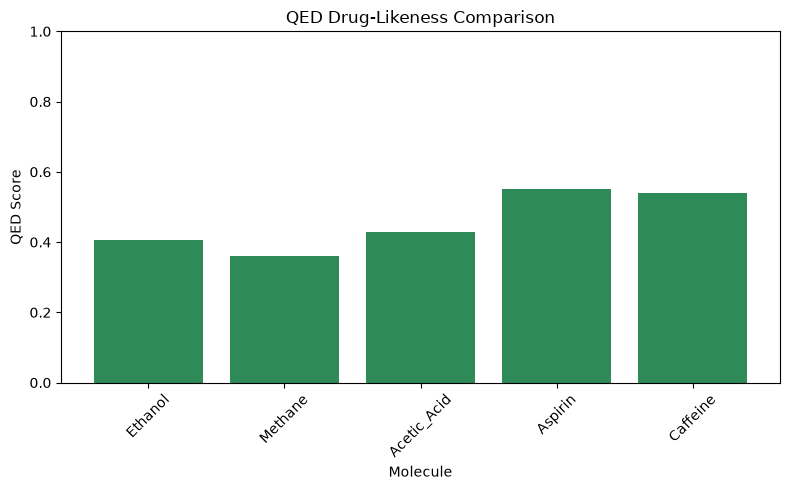

In [41]:
plt.figure(figsize=(8, 5))

plt.bar(
    df["Molecule"],
    df["QED"],
    color="seagreen"
)

plt.xlabel("Molecule")
plt.ylabel("QED Score")
plt.title("QED Drug-Likeness Comparison")
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig("qed_plot.png", dpi=300)
plt.show()

## 10. Conclusion

In this project, I used RDKit to calculate physicochemical descriptors for five molecules (ethanol, methane, acetic acid, aspirin, and caffeine) from their SMILES strings.

**Key findings:**
- Descriptors were calculated correctly. For example, aspirin has a molecular weight of 180.159 and caffeine 194.194, matching known values.
- All five molecules passed Lipinski's Rule of Five with zero violations.
- Aspirin and caffeine had the highest QED drug-likeness scores (about 0.55), while methane had the lowest (about 0.36).
- Validation tests confirmed that invalid SMILES are handled safely and that results are reproducible.

**Possible future work:**
- Apply the pipeline to a larger dataset such as ChEMBL.
- Use the calculated descriptors to train a machine learning model that predicts molecular properties.